# Block 8. Risk model: target, baseline, validation and what weather adds

Plan: `docs/eda-plan.md`, block 8. Results: `docs/findings/08-risk-model.md`.

This notebook does not train anything. It reads what the scripts wrote:

```bash
python scripts/risk_baseline.py
python scripts/risk_model.py --no-weather --out NASA_Data_Sources/processed/risk_no_weather
python scripts/risk_weather.py        # NASA POWER, about 2 hours, resumable
python scripts/risk_model.py          # with weather, writes NASA_Data_Sources/processed/risk/
```

Target: at least one VIIRS hotspot (reference series, quality filter of block 1) in a 0.25° cell
during a week of 7 days. Test years: 2023 to 2025, never seen in training.

In [1]:
import json
import warnings
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

warnings.filterwarnings("ignore", category=DeprecationWarning)  # duckdb -> pandas noise
pd.set_option("display.width", 200, "display.max_columns", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "NASA_Data_Sources").is_dir())
P = ROOT / "NASA_Data_Sources" / "processed"
con = duckdb.connect()
con.execute(f"CREATE VIEW w AS SELECT * FROM read_parquet('{P}/risk/model_eval.parquet')")             # with weather
con.execute(f"CREATE VIEW nw AS SELECT * FROM read_parquet('{P}/risk_no_weather/model_eval.parquet')")  # without
metrics = {"with weather": json.loads((P / "risk" / "model_metrics.json").read_text()),
           "without weather": json.loads((P / "risk_no_weather" / "model_metrics.json").read_text())}


def q(sql: str) -> pd.DataFrame:
    return con.execute(sql).df()


# One row per cell and week of the test years, with the three predictions side by side.
con.execute("""
    CREATE TABLE test AS
    SELECT w.week_start, w.cell_lat, w.cell_lon, w.observed::INT AS fire,
           w.baseline_probability AS p_baseline, nw.probability AS p_history, w.probability AS p_weather
    FROM w JOIN nw USING (week_start, cell_lat, cell_lon)
    WHERE w.observed IS NOT NULL AND year(w.week_start) BETWEEN 2023 AND 2025
""")
q("SELECT count(*) AS cell_weeks, sum(fire) AS with_fire, round(100 * avg(fire), 2) AS pct_with_fire FROM test")

,cell_weeks,with_fire,pct_with_fire
0,746712,70038.0,9.38


## 8.1 The target

Most cell-weeks have no fire, so accuracy is useless as a score: always answering "no fire" is right
about 90% of the time.

In [2]:
q("""
    SELECT year(week_start) AS year, count(*) AS cell_weeks, count(DISTINCT (cell_lat, cell_lon)) AS cells,
           round(100 * avg(observed), 2) AS pct_with_fire
    FROM w WHERE observed IS NOT NULL GROUP BY 1 ORDER BY 1
""").set_index("year").T

year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
cell_weeks,225420.00,233792.00,240240.0,245232.00,248404.00,251420.00,238924.00,255736.00,232744.00,258232.00,219516.00
cells,4335.00,4496.00,4620.0,4716.00,4777.00,4835.00,4876.00,4918.00,4952.00,4966.00,4989.00
pct_with_fire,10.68,10.45,10.8,10.06,14.35,11.09,11.66,9.51,9.08,9.52,8.23


In [3]:
q("""
    WITH per_cell AS (SELECT cell_lat, cell_lon, sum(fire) AS weeks_with_fire, count(*) AS weeks FROM test GROUP BY ALL)
    SELECT CASE WHEN weeks_with_fire = 0 THEN '0' WHEN weeks_with_fire <= 3 THEN '1-3'
                WHEN weeks_with_fire <= 15 THEN '4-15' WHEN weeks_with_fire <= 50 THEN '16-50' ELSE 'over 50' END
               AS weeks_with_fire_2023_2025,
           count(*) AS cells, sum(weeks_with_fire) AS fire_cell_weeks
    FROM per_cell GROUP BY 1 ORDER BY min(weeks_with_fire)
""")

,weeks_with_fire_2023_2025,cells,fire_cell_weeks
0,0,1098,0.0
1,1-3,1303,2269.0
2,4-15,1281,9782.0
3,16-50,799,24506.0
4,over 50,485,33481.0


## 8.2 Baseline against model, with and without weather

- **Baseline:** how often that cell had fire in that week of the year (and the weeks next to it), in
  earlier years only.
- **Model, history only:** the baseline plus fire in the cell and its neighbours in the weeks before.
- **Model, with weather:** the same plus ten NASA POWER features of the days before the week.

Average precision and Brier score are the ones to read. Lower Brier is better.

In [4]:
rows = []
for name, m in metrics.items():
    rows.append({"model": f"model, {name}", **{k: m["model"][k] for k in ["average_precision", "brier", "roc_auc"]}})
rows.insert(0, {"model": "baseline", **{k: metrics["with weather"]["baseline"][k] for k in ["average_precision", "brier", "roc_auc"]}})
overall = pd.DataFrame(rows).set_index("model").round(4)
overall

,average_precision,brier,roc_auc
model,,,
baseline,0.5100,0.0616,0.8869
"model, with weather",0.5625,0.0572,0.9016
"model, without weather",0.5550,0.0577,0.9002


In [5]:
per_year = pd.DataFrame({
    (yr, col): {"baseline": metrics["with weather"]["per_year"][yr]["baseline"][key],
                "model, history only": metrics["without weather"]["per_year"][yr]["model"][key],
                "model, with weather": metrics["with weather"]["per_year"][yr]["model"][key]}
    for yr in ["2023", "2024", "2025"] for col, key in [("avg precision", "average_precision"), ("Brier", "brier")]
}).round(4)
per_year

2023                  2024                  2025        
                    avg precision   Brier avg precision   Brier avg precision   Brier
baseline                   0.4745  0.0654        0.5501  0.0573        0.5138  0.0616
model, history only        0.5269  0.0606        0.5705  0.0552        0.5692  0.0571
model, with weather        0.5342  0.0603        0.5818  0.0545        0.5728  0.0567

What the scores mean in practice: if a team could only watch the cell-weeks with the highest
predicted probability, how much of the fire activity would fall inside them?

In [6]:
t = q("SELECT fire, p_baseline, p_history, p_weather FROM test")
total = t.fire.sum()
capture = {}
for col, label in [("p_baseline", "baseline"), ("p_history", "model, history only"), ("p_weather", "model, with weather")]:
    ranked = t.sort_values(col, ascending=False).fire.to_numpy()
    capture[label] = {f"top {int(100 * s)}%": round(100 * ranked[: int(len(ranked) * s)].sum() / total, 1)
                      for s in [0.01, 0.05, 0.10, 0.20]}
pd.DataFrame(capture).T.rename_axis("% of fire cell-weeks inside the top-ranked cell-weeks")

,top 1%,top 5%,top 10%,top 20%
% of fire cell-weeks inside the top-ranked cell-weeks,,,,
baseline,8.6,32.7,52.6,74.9
"model, history only",8.8,35.4,56.7,78.1
"model, with weather",8.9,36.0,57.1,78.5


Is the probability honest? Group the test cell-weeks by predicted probability and compare with how
often fire really happened.

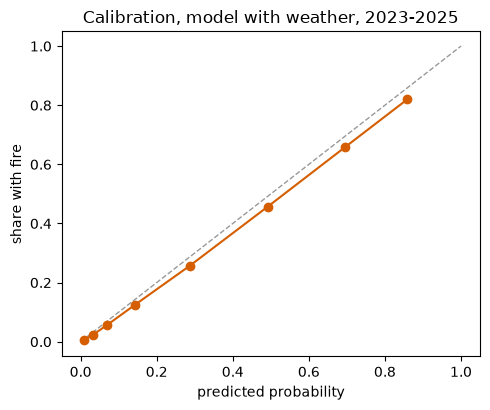

,cell_weeks,predicted,observed
bin,,,
"[0.0, 0.02)",289080,0.009,0.006
"[0.02, 0.05)",178028,0.032,0.023
"[0.05, 0.1)",93435,0.070,0.057
"[0.1, 0.2)",66283,0.143,0.125
"[0.2, 0.4)",59269,0.287,0.257
"[0.4, 0.6)",30205,0.492,0.457
"[0.6, 0.8)",21149,0.695,0.658
"[0.8, 1.0)",9263,0.859,0.820


In [7]:
bins = [0, 0.02, 0.05, 0.1, 0.2, 0.4, 0.6, 0.8, 1.0001]
cal = t.assign(bin=pd.cut(t.p_weather, bins, right=False)).groupby("bin", observed=True).agg(
    cell_weeks=("fire", "size"), predicted=("p_weather", "mean"), observed=("fire", "mean")).round(3)
fig, ax = plt.subplots(figsize=(5, 4.2))
ax.plot([0, 1], [0, 1], color="#999", ls="--", lw=1)
ax.plot(cal.predicted, cal.observed, marker="o", color="#D55E00")
ax.set(title="Calibration, model with weather, 2023-2025", xlabel="predicted probability", ylabel="share with fire")
fig.tight_layout()
fig.savefig(ROOT / "docs" / "findings" / "08-calibration.png", dpi=130)
plt.show()
cal

## What weather adds

Feature importance (share of the total gain) of the model with weather.

In [8]:
gain = pd.Series(metrics["with weather"]["feature_importance_gain"])
(100 * gain / gain.sum()).round(1).rename("% of gain").to_frame().T

,baseline_probability,fire_prev_4w,nbr_fire_prev_1w,fire_prev_1w,cell_lon,ante_days_since_rain,week_sin,week_cos,cell_lat,ante_precip_30d_mm,ante_dry_days_30d,ante_tmax_14d_c,ante_soil_wet,ante_rh_14d_pct,ante_vpd_14d_kpa,ante_precip_90d_mm,ante_wind_7d_ms,ante_wind_max_7d_ms
% of gain,56.4,28.6,7.6,1.9,1.1,1.0,0.6,0.6,0.5,0.3,0.3,0.2,0.2,0.1,0.1,0.1,0.1,0.1


## 8.3 Persistence

How much of the signal is simply "it burned last week"?

In [9]:
q("""
    WITH lagged AS (
        SELECT cell_lat, cell_lon, week_start, observed AS fire,
               lag(observed) OVER (PARTITION BY cell_lat, cell_lon ORDER BY week_start) AS fire_before,
               lag(week_start) OVER (PARTITION BY cell_lat, cell_lon ORDER BY week_start) AS week_before
        FROM w WHERE observed IS NOT NULL)
    SELECT CASE WHEN fire_before = 1 THEN 'fire the week before' ELSE 'no fire the week before' END AS situation,
           count(*) AS cell_weeks, round(100 * avg(fire), 1) AS pct_with_fire
    FROM lagged
    WHERE fire_before IS NOT NULL AND week_start - week_before <= 8 AND year(week_start) BETWEEN 2023 AND 2025
    GROUP BY 1 ORDER BY 1
""")

,situation,cell_weeks,pct_with_fire
0,fire the week before,68179,45.8
1,no fire the week before,658635,5.5


## 8.4 Information leaks: what was checked

| Risk | How the scripts avoid it | Check |
|---|---|---|
| Test years seen in training | Train up to 2020, tune on 2021-2022, test on 2023-2025 | `scripts/risk_model.py` |
| Baseline built with the year it predicts | Baseline of year Y uses years before Y only | `tests/test_risk_baseline.py` |
| Cells chosen because they burn later | Year Y is scored on cells with a detection before Y | `tests/test_risk_baseline.py` |
| Features from inside the week | Lags end the week before; weather windows end the day before the week | Code read, `risk_weather.py` `shift(1)` |
| Target that grows with the number of satellites | One satellite at a time (Suomi-NPP, then NOAA-20) | `scripts/risk_baseline.py` |
| Weeks with a satellite outage counted as "no fire" | Outage weeks are not observed | `scripts/risk_baseline.py` |

Not checked: whether the harmonization factors leak (they do not enter the model, which uses VIIRS
only), and whether near-real-time rows of 2026 will change after FIRMS revises them.

## 8.5 Weather coverage and alignment

In [10]:
weather = q(f"""
    SELECT count(*) AS point_weeks, count(DISTINCT (point_lat, point_lon)) AS points,
           min(week_start) AS first_week, max(week_start) AS last_week,
           round(100 * avg((ante_precip_30d_mm IS NULL)::INT), 2) AS pct_missing
    FROM read_parquet('{P}/weather/weekly.parquet')
""")
weather

,point_weeks,points,first_week,last_week,pct_missing
0,1133218,1466,2012-01-01,2026-11-05,0.0


In [11]:
q("SELECT max(week_start) AS last_week_in_risk_file, max(week_start) FILTER (WHERE source = 'model') AS last_model_week FROM w")

,last_week_in_risk_file,last_model_week
0,2027-01-01,2026-11-12


## A known case: Valparaíso, week of 29 January to 4 February 2024

2024 is a test year, so this is what the model would have said without having seen it.
Percentile: share of all cells that week with a lower probability.

In [12]:
con.execute("""
    CREATE TABLE week AS SELECT *, percent_rank() OVER (ORDER BY p_weather) AS pct_weather,
                                percent_rank() OVER (ORDER BY p_baseline) AS pct_baseline
    FROM test WHERE week_start = DATE '2024-01-29'
""")
q("""
    SELECT cell_lat, cell_lon, fire, round(p_baseline, 3) AS p_baseline, round(p_history, 3) AS p_history,
           round(p_weather, 3) AS p_weather, round(100 * pct_baseline) AS percentile_baseline,
           round(100 * pct_weather) AS percentile_weather
    FROM week WHERE cell_lon < -71.30 AND cell_lon + 0.25 > -71.70 AND cell_lat < -32.95 AND cell_lat + 0.25 > -33.25
    ORDER BY 1, 2
""")

,cell_lat,cell_lon,fire,p_baseline,p_history,p_weather,percentile_baseline,percentile_weather
0,-33.25,-71.75,1,0.066,0.110,0.112,70.0,81.0
1,-33.25,-71.50,1,0.393,0.461,0.477,96.0,98.0
2,-33.00,-71.75,0,0.030,0.040,0.042,54.0,63.0
3,-33.00,-71.50,1,0.319,0.259,0.280,93.0,92.0


In [13]:
q("SELECT count(*) AS cells_that_week, round(100 * avg(fire), 1) AS pct_with_fire, round(avg(p_weather), 3) AS mean_p_weather FROM week")

,cells_that_week,pct_with_fire,mean_p_weather
0,4952,10.7,0.076
